# Submission Summary

| Item | Information |
|---|---|
| Group number | 28 |
| Your full name | Adeniyi Paul Adeyemi |
| Dataset | Stroke Prediction |
| Depth track | Classification Depth |
| Team members | Udeme Chiedozie Kufre Esien, Atanda Eniola Temiloluwa, Abebor Almond Onanefe, Omadudu Lesley Akpesiri, Adelusola Susan Abimbola, Akintola Olajumoke Ayomide |
| Final model | Logistic Regression, no class weights, cost-tuned threshold 0.08 |
| Stratified dummy F1 / ROC AUC | 0.04 / 0.50 |
| Final model F1 / ROC AUC | 0.30 / 0.85 |
| Leakage columns dropped | None found (`id` dropped as an identifier, `cluster` kept out of the model) |
| Full run time on Colab | Under 2 minutes |

In [1]:
%pip install -q kagglehub

In [2]:
import kagglehub
import pandas as pd
import os
import sqlite3

# Part 1. Data Foundation

### 1. Load the dataset from Kaggle inside the notebook and push it into a SQLite database.

In [3]:
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")
print(path)
print(os.listdir(path))

file_path = os.path.join(path, "healthcare-dataset-stroke-data.csv")
df = pd.read_csv(file_path)
df_copy = df.copy()

Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.
/kaggle/input/stroke-prediction-dataset
['healthcare-dataset-stroke-data.csv']


In [4]:
# Pushing dataset into SQLite database

conn = sqlite3.connect(":memory:")
df.to_sql("stroke_data", conn, index=False)

5110

In [5]:
# Checking the first 5 rows of the dataset using SQL query
sql_query = pd.read_sql_query("""SELECT * FROM stroke_data LIMIT 5""", conn)
print(sql_query)

      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  


### 2. Run at least three SQL queries that reveal something useful, each followed by a markdown cellexplaining what you learned

In [6]:
pd.read_sql("""
SELECT DISTINCT smoking_status
FROM stroke_data;
""", conn)

,smoking_status
0,formerly smoked
1,never smoked
2,smokes
3,Unknown


With the above SQL query we were able to figure out the various category of patients in our dataset as relates to their smoking status.

In [7]:
pd.read_sql("""
SELECT smoking_status, COUNT(*) AS num_people
FROM stroke_data
GROUP BY smoking_status
ORDER BY num_people DESC;
""", conn)

,smoking_status,num_people
0,never smoked,1892
1,Unknown,1544
2,formerly smoked,885
3,smokes,789


With the above SQL query we were able to figure out the number of patients in the various category as relates to their smoking status.

In [8]:
pd.read_sql("""
SELECT
    SUM(heart_disease) AS total_heart_disease,
    AVG(age) AS average_age
FROM stroke_data
WHERE heart_disease = 1;
""", conn)

,total_heart_disease,average_age
0,276,68.188406


With the above SQL query we were able to figure out the median age of the patients with heart disease.

In [9]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### 3. Performing EDA: shape, types, missing values, target distribution, and three to five feature distributions.

In [10]:
df.shape

(5110, 12)

In [11]:
df.dtypes

,0
id,int64
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64


In [12]:
df_copy.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [13]:
missing_bmi = df["bmi"].isnull().sum()
missing_bmi_percentage = (missing_bmi / len(df)) * 100

print("Missing BMI:", missing_bmi)
print("Percentage missing:", missing_bmi_percentage)

Missing BMI: 201
Percentage missing: 3.9334637964774952


In [14]:
df.groupby(df["bmi"].isnull())["stroke"].mean()

,stroke
bmi,
False,0.042575
True,0.199005


In [15]:
df.groupby(df["bmi"].isnull())["age"].mean()

,age
bmi,
False,42.865374
True,52.049154


In [16]:
df["bmi"].describe()

,bmi
count,4909.000000
mean,28.893237
std,7.854067
min,10.300000
25%,23.500000
50%,28.100000
75%,33.100000
max,97.600000


# Commented out the code below because it violates a statement(_No blanket  fillna . If you drop rows, explain why_) contained in number 4 of Part 1 of the deliverables

In [17]:
#median_bmi = df["bmi"].median()
#df["bmi"] = df["bmi"].fillna(median_bmi)

In [18]:
df["bmi"].isnull().sum()

np.int64(201)

In [19]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [20]:
df["stroke"].value_counts()

,count
stroke,
0,4861
1,249


In [21]:
df["stroke"].value_counts(normalize=True) * 100

,proportion
stroke,
0,95.127202
1,4.872798


In [22]:
df["age"].describe()

,age
count,5110.000000
mean,43.226614
std,22.612647
min,0.080000
25%,25.000000
50%,45.000000
75%,61.000000
max,82.000000


### Age Distribution:

The dataset contains individuals across a broad range of ages, from infants to 82 years old. The average age is approximately 43 years, while the median age is 45 years.

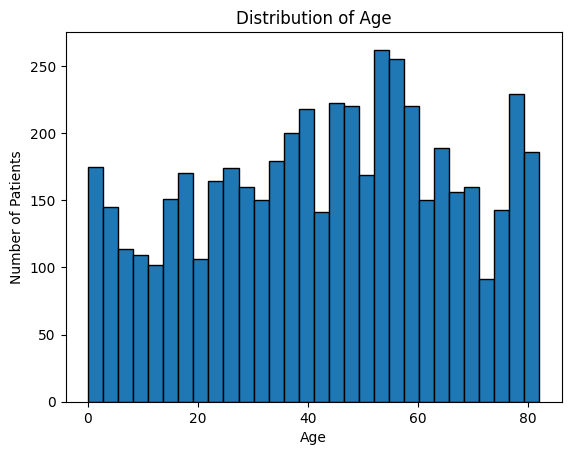

In [23]:
import matplotlib.pyplot as plt

plt.hist(df["age"], bins=30, edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.title("Distribution of Age")
plt.show()

In [24]:
df["avg_glucose_level"].describe()

,avg_glucose_level
count,5110.000000
mean,106.147677
std,45.283560
min,55.120000
25%,77.245000
50%,91.885000
75%,114.090000
max,271.740000


### Average Glucose Level Distribution:

The distribution is right-skewed. Most patients have lower to moderate glucose levels, while a smaller number have much higher values, which pulls the mean above the median.

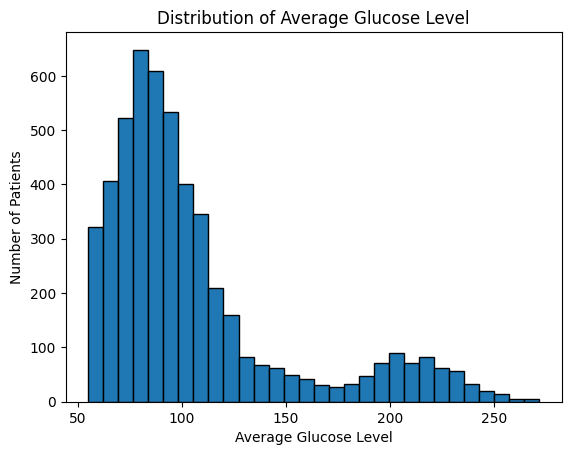

In [25]:
plt.hist(df["avg_glucose_level"], bins=30, edgecolor="black")
plt.xlabel("Average Glucose Level")
plt.ylabel("Number of Patients")
plt.title("Distribution of Average Glucose Level")
plt.show()

In [26]:
df["bmi"].describe()

,bmi
count,4909.000000
mean,28.893237
std,7.854067
min,10.300000
25%,23.500000
50%,28.100000
75%,33.100000
max,97.600000


### BMI Distribution:

BMI is slightly right-skewed, with most observations concentrated around the mid-20s to low-30s. A few unusually high BMI values are present, including a maximum of 97.6. These values were retained because a high value alone is not sufficient evidence that the observation is incorrect.

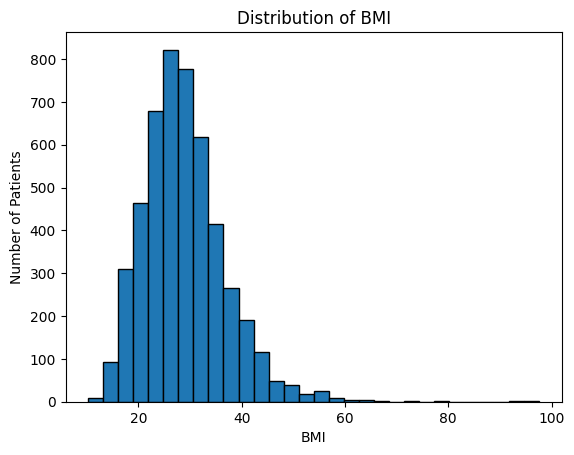

In [27]:
plt.hist(df["bmi"], bins=30, edgecolor="black")
plt.xlabel("BMI")
plt.ylabel("Number of Patients")
plt.title("Distribution of BMI")
plt.show()

In [28]:
df["smoking_status"].value_counts()

,count
smoking_status,
never smoked,1892
Unknown,1544
formerly smoked,885
smokes,789


In [29]:
df["smoking_status"].value_counts(normalize=True) * 100

,proportion
smoking_status,
never smoked,37.025440
Unknown,30.215264
formerly smoked,17.318982
smokes,15.440313


### Smoking Status Distribution:

The largest group consists of individuals who never smoked (37.0%), followed by individuals with unknown smoking status (30.2%). Former smokers account for 17.3%, while current smokers account for 15.4%. The relatively large Unknown category should be retained as a separate category because it represents unavailable information rather than confirmed non-smoking.

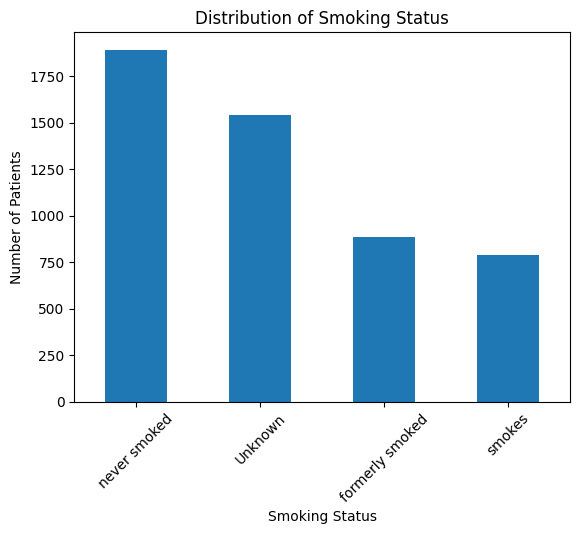

In [30]:
df["smoking_status"].value_counts().plot(kind="bar")

plt.xlabel("Smoking Status")
plt.ylabel("Number of Patients")
plt.title("Distribution of Smoking Status")
plt.xticks(rotation=45)
plt.show()

In [31]:
df["hypertension"].value_counts()

,count
hypertension,
0,4612
1,498


### Hypertension Distribution:

Most individuals in the dataset do not have hypertension (90.3%), while approximately 9.7% have hypertension. Although the column is stored as an integer, it represents a binary categorical variable where 0 means no hypertension and 1 means hypertension.

In [32]:
df["hypertension"].value_counts(normalize=True) * 100

,proportion
hypertension,
0,90.254403
1,9.745597


### 4. Clean the data, justifying every step in markdown. No blanket  fillna . If you drop rows, explain why.

### Duplicate Check:

No exact duplicate rows were found in the dataset, so no rows were removed for duplication.

In [33]:
df.duplicated().sum()

np.int64(0)

In [34]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [35]:
df[df["bmi"].isnull()].sample(10)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2997,4498,Male,71.0,0,1,Yes,Private,Urban,204.98,NaN,formerly smoked,0
3059,121,Female,38.0,0,0,Yes,Private,Urban,91.44,NaN,Unknown,0
1306,1678,Female,54.0,1,0,Yes,Private,Rural,98.74,NaN,never smoked,0
1102,18414,Female,23.0,0,0,No,Private,Rural,193.22,NaN,smokes,0
4286,23339,Male,3.0,0,0,No,children,Rural,194.75,NaN,Unknown,0
936,224,Female,23.0,0,0,No,Private,Urban,110.16,NaN,never smoked,0
3074,72231,Female,47.0,0,0,Yes,Self-employed,Rural,195.61,NaN,never smoked,0
2105,34248,Male,50.0,1,0,No,Private,Urban,81.96,NaN,formerly smoked,0
133,31563,Female,38.0,0,0,Yes,Private,Rural,101.45,NaN,formerly smoked,1
1779,18861,Male,32.0,0,0,No,Private,Rural,95.58,NaN,smokes,0


In [36]:
df[~df["bmi"].isnull()].sample(10)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
179,65105,Male,81.0,0,0,Yes,Private,Urban,213.22,26.1,Unknown,1
383,22537,Male,5.0,0,0,No,children,Rural,85.84,16.4,Unknown,0
1327,51285,Female,46.0,0,0,Yes,Private,Urban,61.81,25.5,Unknown,0
1982,20310,Male,25.0,0,0,No,Govt_job,Urban,75.50,24.6,never smoked,0
52,59190,Female,79.0,0,1,Yes,Private,Rural,127.29,27.7,never smoked,1
1202,19778,Male,80.0,0,0,No,Self-employed,Rural,204.17,41.3,formerly smoked,0
4576,66786,Female,53.0,0,0,Yes,Private,Rural,94.14,27.7,smokes,0
822,69645,Male,61.0,0,0,Yes,Govt_job,Rural,112.95,22.2,formerly smoked,0
4902,65333,Female,31.0,0,0,Yes,Private,Rural,96.03,24.1,Unknown,0
1087,16147,Female,19.0,0,0,No,Private,Rural,106.56,29.9,never smoked,0


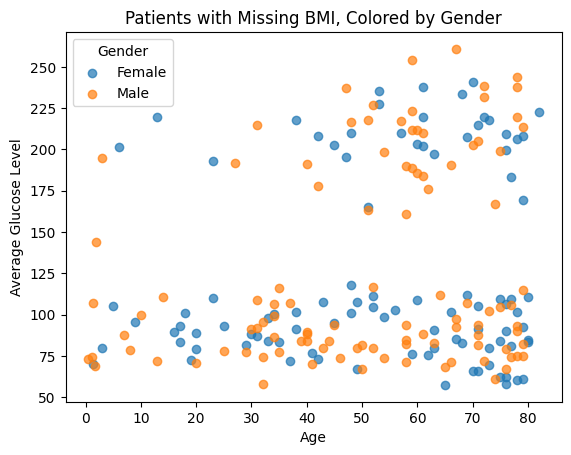

In [37]:
missing_bmi = df[df["bmi"].isna()]

for gender, group in missing_bmi.groupby("gender"):
    plt.scatter(
        group["age"],
        group["avg_glucose_level"],
        label=gender,
        alpha=0.7
    )

plt.xlabel("Age")
plt.ylabel("Average Glucose Level")
plt.title("Patients with Missing BMI, Colored by Gender")
plt.legend(title="Gender")
plt.show()

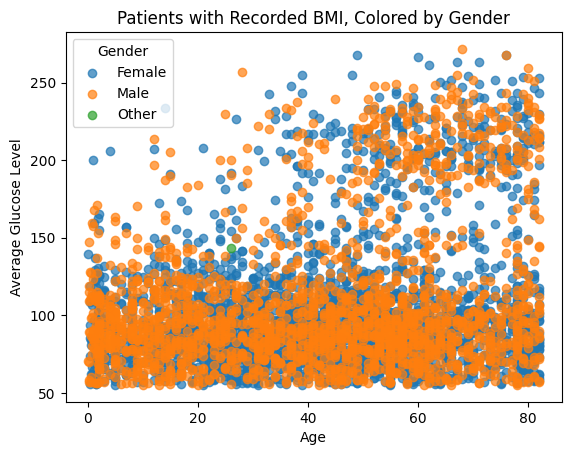

In [38]:
# Keep only patients who have a recorded BMI value.
recorded_bmi = df[df["bmi"].notna()]

# Plot each gender separately; age and average glucose are the axes.
for gender, group in recorded_bmi.groupby("gender"):
    plt.scatter(
        group["age"],
        group["avg_glucose_level"],
        label=gender,
        alpha=0.7
    )

# Label the axes and title, add a gender legend, and display the plot.
plt.xlabel("Age")
plt.ylabel("Average Glucose Level")
plt.title("Patients with Recorded BMI, Colored by Gender")
plt.legend(title="Gender")
plt.show()

In [39]:
# Select patients whose BMI is missing.
missing_bmi = df[df["bmi"].isna()]

# Count those with average glucose at least 150 and at most 150.
count_150_and_above = (missing_bmi["avg_glucose_level"] >= 150).sum()
count_150_and_below = (missing_bmi["avg_glucose_level"] <= 150).sum()

# Print both counts. A glucose value of exactly 150 is included in both.
print("BMI missing, glucose >= 150:", count_150_and_above)
print("BMI missing, glucose <= 150:", count_150_and_below)

BMI missing, glucose >= 150: 65
BMI missing, glucose <= 150: 136


In [40]:
# Select patients who have a recorded BMI value.
recorded_bmi = df[df["bmi"].notna()]

# Count those with average glucose at least 150 and at most 150.
count_150_and_above = (recorded_bmi["avg_glucose_level"] >= 150).sum()
count_150_and_below = (recorded_bmi["avg_glucose_level"] <= 150).sum()

# Print both counts. A glucose value of exactly 150 is included in both.
print("BMI recorded, glucose >= 150:", count_150_and_above)
print("BMI recorded, glucose <= 150:", count_150_and_below)

BMI recorded, glucose >= 150: 666
BMI recorded, glucose <= 150: 4244


In [41]:
# Select only numeric columns from the dataframe.
numeric_data = df.select_dtypes(include="number")

# Calculate correlations with BMI, then remove BMI's correlation with itself.
bmi_correlations = numeric_data.corr()["bmi"].drop("bmi")

# Sort the results from strongest to weakest by absolute correlation.
bmi_correlations = bmi_correlations.reindex(
    bmi_correlations.abs().sort_values(ascending=False).index
)

# Display the correlations in a labeled table.
display(bmi_correlations.to_frame("correlation_with_bmi"))

,correlation_with_bmi
age,0.333398
avg_glucose_level,0.175502
hypertension,0.167811
stroke,0.042374
heart_disease,0.041357
id,0.003084


In [42]:
#Checking how many entries with age less than 1 year are present in the dataset
df[df['age'] < 1].count()

,0
id,43
gender,43
age,43
hypertension,43
heart_disease,43
ever_married,43
work_type,43
Residence_type,43
avg_glucose_level,43
bmi,42


In [43]:
# Divide ages into ranges and store each patient's range in a new column.
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 18, 35, 50, 65, 100],
    labels=["0-18", "19-35", "36-50", "51-65", "66+"]
)

In [44]:
# Count the number of patients in each age group, keeping the age order.
age_group_counts = df["age_group"].value_counts(sort=False)

# Display the counts in a table.
display(age_group_counts.to_frame("number_of_patients"))

,number_of_patients
age_group,
0-18,916
19-35,983
36-50,1084
51-65,1162
66+,965


In [45]:
# Exclude rows missing either BMI or age group.
recorded_bmi = df.dropna(subset=["bmi", "age_group"])

# Group the remaining patients by age group and calculate BMI mean and median.
bmi_by_age_group = (
    recorded_bmi
    .groupby("age_group", observed=False)["bmi"]
    .agg(mean_bmi="mean", median_bmi="median")
)

# Display the summary table.
display(bmi_by_age_group)

,mean_bmi,median_bmi
age_group,,
0-18,21.714302,20.1
19-35,29.131342,27.4
36-50,31.397812,30.0
51-65,31.670699,30.5
66+,29.415118,28.8


In [46]:
# Calculate each age group's median using only rows with recorded BMI.
# Convert the categorical age groups to strings to make the mapping consistent.
bmi_medians_by_age = (
    df.dropna(subset=["bmi", "age_group"])
      .assign(age_group=lambda data: data["age_group"].astype(str))
      .groupby("age_group")["bmi"]
      .median()
)

# Look up the matching age-group median for each row.
bmi_estimates = df["age_group"].astype(str).map(bmi_medians_by_age)

# Ensure BMI is a float column, then fill only its missing values with the estimates.
df["bmi"] = df["bmi"].astype("float64").fillna(bmi_estimates)

# Check whether any BMI values remain missing.
print("BMI values still missing:", df["bmi"].isna().sum())

BMI values still missing: 0


Finding the correlation between the BMI column and each of every other numerical column in the dataset we were able to establish that the age columns is most strongly correlated with the BMI column.

Next, we grouped the ages into four parts(_"0-18", "19-35", "36-50", "51-65", "66+"_). Then we created a new column(*age_group*) that indicate which age group each row of data belong to.

Next, we found the mean and median _BMI_ for each group, where _BMI_ is not null. Since the mean and median were almost the the same for each age group, we then filled up the null _BMIs_ with the corresponding medain values of the *age_group* each rows of data belong to.

# Part 2. Feature Engineering and Encoding

#### Feature: Age Group
As age increases the  likelihood of having a stroke generally increases. As people get older, changes can occur in the blood vessels and the body becomes more susceptible to condition like hypertention. Grouping the ages makes it easier to see the pattern more clearly than raw numeric age.

In [47]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 35, 60, 100],
    labels=['Child', 'Young adult', 'Middle-aged', 'Senior']
)

#### Feature: Cardiovascular Condition Score
This feature combines hypertension and heart disease into one variable. Both conditions are associated with an increased risk of stroke, so combining them makes it easier to see whether a person has one or both of these known risk factors. it also givees the clustering alogrithm a simple way to capture the combined presence of these conditions.

In [48]:
df['cardiovascular_condition_score'] = ((df['hypertension'] == 1) | (df['heart_disease'] == 1)).astype(int)

#### Feature: Glucose to BMI Ratio
This feature is created by dividing the average glucose level by BMI. Glucose level and BMI provide different information about an individual's health and combining them allows us to explore whether their relationship reveals patterns that may not be as obvious whe  looking at each varaible separately. A higher ratio means that the person's glucose level os relatively high compared with their BMI.

In [49]:
df['glucose_bmi_ratio'] = df['avg_glucose_level'] / df['bmi']

In [50]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,age_group,cardiovascular_condition_score,glucose_bmi_ratio
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1,Senior,1,6.248361
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,30.5,never smoked,1,Senior,0,6.629836
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1,Senior,1,3.259077
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1,Middle-aged,0,4.977616
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1,Senior,1,7.255000


### Encoding: Categorical Variables
Since the categorical variables are norminal and have no natural order, one-hot encoding is used instead of label encoding, because label encoding could incorrectly imply a ranking between the categories. One-hot encoding creates a separate binary column for each category, allowing the model to treat them as distinct groups without assuming any order. drop_first=True is used for these variables because one category can be inferred from the remaining categories. Removing this category reduces redundant columns while retaining the information needed to represent the original varaible.

In [51]:
df = pd.get_dummies(
    df,
    columns=['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status'],
    drop_first=True
)

#### Encoding: Age Group
Unlike gender, work_type, Residence_type, and smoking_status. which are nominal categories with no ranking, age group is encoded according to it's natural order, since the categories progress from younger to older age groups. This preserves the ordered relationship between the age categories rather than treating them as unrelated groups.

In [52]:
age_order = {'Child': 0, 'Young adult': 1, 'Middle-aged': 2, 'Senior': 3}
df['age_group'] = df['age_group'].map(age_order).astype(int)

### Feature Scaling
The numeric columns in this dataset are on very different scales. For example, age ranges from about 0 to 82, while avg_glucose_level ranges up to 270+. If left unscaled, K-Means may give more influence to variables with larger numerical values simply because of their sclae, rather than because they are more important. StandardScaler was chosen over MinMaxScaler because the dataset contains an extreme outlier in bmi (max value 97.6). MinMaxScaler would compress most normal values into a very narrow range to accommodate that one outlier, distorting the scale for everyone else. StandardScaler instead centers each feature around its mean and scales it according to its standard deviation. This puts all numeric features on the same comparable scale without letting a single outlier dominate the transformation. This is particularly important for K-Means because the alogrithm uses distances to determine which observations are most similar.

In [53]:
from sklearn.preprocessing import StandardScaler

numeric_cols = ['age', 'avg_glucose_level', 'bmi', 'glucose_bmi_ratio']

scaler = StandardScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

In [54]:
df[numeric_cols].describe()

,age,avg_glucose_level,bmi,glucose_bmi_ratio
count,5.110000e+03,5.110000e+03,5.110000e+03,5.110000e+03
mean,5.005781e-17,1.001156e-16,-3.170328e-16,-3.086898e-16
std,1.000098e+00,1.000098e+00,1.000098e+00,1.000098e+00
min,-1.908261e+00,-1.126958e+00,-2.405088e+00,-1.896284e+00
25%,-8.061152e-01,-6.383223e-01,-6.694903e-01,-7.180036e-01
50%,7.843218e-02,-3.149945e-01,-8.664046e-02,-2.463654e-01
75%,7.860701e-01,1.754080e-01,5.091616e-01,4.705004e-01
max,1.714845e+00,3.657145e+00,8.902199e+00,7.133396e+00


# Part 3. Clustering Analysis

Stroke is excluded from clustering because it is our target variable. Since clustering is meant to discover natural groupings in the data without using the outcome we're trying to understand, all other engineered, encoded, and scaled features are included. This allows us to see whether natural groups in the data have diiferent stroke rates later on.

In [55]:
X_cluster = df.drop(columns=['stroke', 'id'])

In [56]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertias = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_cluster, labels))

##### Plotting the elbow curve

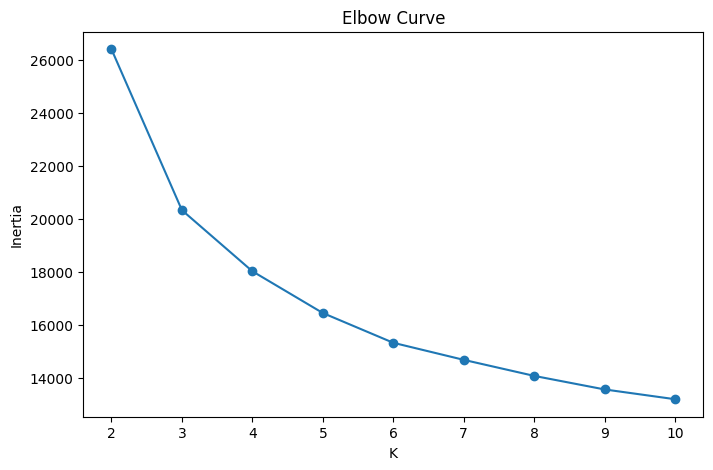

In [57]:
plt.figure(figsize=(8,5))
plt.plot(K_range, inertias, marker='o')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.title('Elbow Curve')
plt.show()

##### Plotting the silhouette score

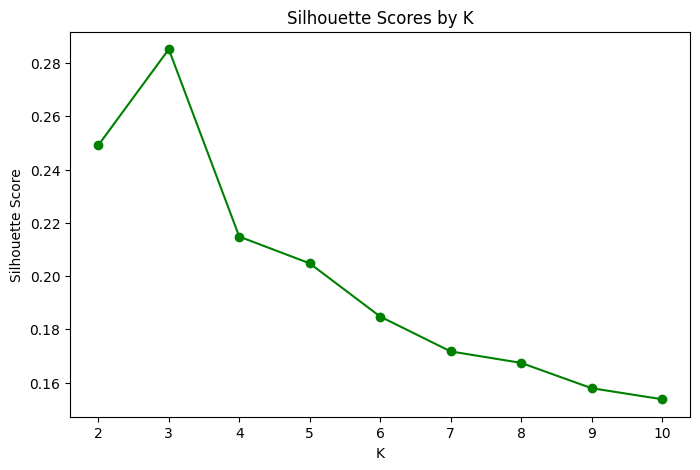

In [58]:
plt.figure(figsize=(8,5))
plt.plot(K_range, sil_scores, marker='o', color='green')
plt.xlabel('K')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores by K')
plt.show()

##### Choosing Final K: K3 was selected as the final number of clusters.
The elbow curve shows a sharp decrease in inertia from K=2 to K=3 (from 26000 to 20000). After K=4, the decrease in inertia becomes smaller and the curve flattens out, suggesting that adding more clusters provides less improvement and is just over-slicing. The silhouette score, which shows how well-separated clusters are from each other, also supports K=3, the score increases from 0.24 at K=2 to 0.28 at K=3, then declines steadily for every K after. Choosing a higher K only splits already well-formed groups into smaller, less meaningful pieces.

In [59]:
final_k = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = final_k.fit_predict(X_cluster)

df['cluster'].value_counts()

,count
cluster,
0,2831
2,1580
1,699


In [60]:
profile_cols = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease', 'stroke']

df.groupby('cluster')[profile_cols].mean()

,age,avg_glucose_level,bmi,hypertension,heart_disease,stroke
cluster,,,,,,
0,0.468558,-0.381637,0.297378,0.111621,0.057577,0.054045
1,0.789866,2.167392,0.453554,0.250358,0.157368,0.134478
2,-1.188990,-0.275059,-0.733489,0.004430,0.001899,0.001266


In [61]:
# Reversing the scaling to get real-world values back for interpretation
import numpy as np

original_values = scaler.inverse_transform(df[numeric_cols])
df_original_scale = pd.DataFrame(original_values, columns=numeric_cols, index=df.index)
df_original_scale['cluster'] = df['cluster']

df_original_scale.groupby('cluster')[['age', 'avg_glucose_level', 'bmi']].mean()

,age,avg_glucose_level,bmi
cluster,,,
0,53.820911,88.867492,31.164889
1,61.085837,204.285293,32.370672
2,16.343038,93.693253,23.205886


##### Cluster Profiling

Cluster 0 — "Middle-Aged, Moderate Risk" (2,831 patients): Average age 53.8, average glucose 88.9 (within normal range), average BMI 31.1 (obese range). Hypertension and heart disease rates are moderate, and the stroke rate (5.4%) is close to the overall dataset average (~4.9%).

Cluster 1 — "Young Adults, Low Risk" (1,580 patients): Average age just 16.3, average BMI 23.3 (normal range). Hypertension, heart disease and stroke rates are all near zero (0.1% stroke rate), consistent with a young, low-risk population.

Cluster 2 — "Older Adults with Diabetic-Range Glucose" (699 patients): Average age 61, average glucose 204.3 within the clinically diabetic range (126+ mg/dL). This group has the highest rates of hypertension (25.1%) and heart disease (15.8%), and the highest stroke rate by far at 13.5%, nearly 3x the overall dataset average.


#### PCA Visualization

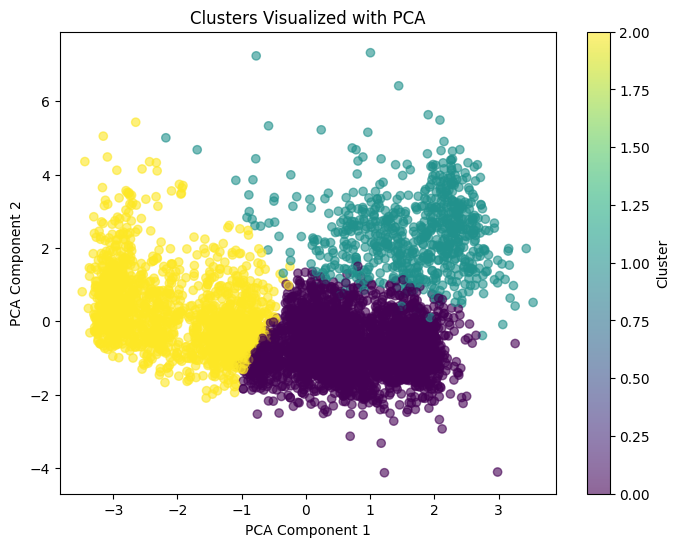

In [62]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.6)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('Clusters Visualized with PCA')
plt.colorbar(scatter, label='Cluster')
plt.show()

##### PCA Visualization — Interpretation

The PCA plot shows three visually distinguishable clusters. Cluster 1 (teal, young/low-risk) is clearly separated from the other two groups, consistent with its much lower average age (16.3) and near-zero rates of hypertension, heart disease, and stroke. Clusters 0 (purple) and 2 (yellow) sit closer together with some overlap, which aligns with their more similar average ages (53.8 and 61), these two groups share more characteristics with each other than either does with Cluster 1, even though Cluster 2 stands out with much higher average glucose and stroke rate.

# Part 4. Classification

### 1. Set up the task with train_test_split and stratify=y

The goal is to predict `stroke` (1 = the patient had a stroke, 0 = no stroke) from the cleaned, engineered and encoded features built in Parts 1 and 2.

Two columns are kept out of the feature matrix on purpose. `id` is only a row identifier, so it carries no medical information and would only let a model memorise rows. `cluster` is the output of an unsupervised model from Part 3. It is left out so the classifier is built from the patient data alone, and so that Part 6 can test the clusters against the label as an independent check.

The dataset has 5,110 rows, which is above the 2,000-row threshold in the brief, so a single stratified hold-out split is used instead of cross-validation (cross-validation is still used in the Depth Track). `stratify=y` is essential here because only about 4.9% of patients had a stroke. Without it, a random split could leave the test set with very few positive cases and make every metric unstable. An 80/20 split with `random_state=42` keeps enough positives in training to learn from and enough in the test set to measure.

A note on honesty: BMI imputation and scaling were done in Parts 1 and 2 on the full dataset before this split. Both steps only use feature values (never the label), and tree-based models are unaffected by scaling, so the leakage risk is very small, but a production pipeline would fit them on the training rows only.

In [63]:
import numpy as np
from sklearn.model_selection import train_test_split

# Feature matrix: drop the identifier, the target and the Part 3 cluster label.
X = df.drop(columns=['id', 'stroke', 'cluster']).astype(float)
y = df['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Features used:", X.shape[1])
print("Train rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])
print("Stroke rate in train: {:.2f}%".format(y_train.mean() * 100))
print("Stroke rate in test:  {:.2f}%".format(y_test.mean() * 100))
print("Positive cases in test set:", int(y_test.sum()))

Features used: 19
Train rows: 4088 | Test rows: 1022
Stroke rate in train: 4.87%
Stroke rate in test:  4.89%
Positive cases in test set: 50


### 2. Train at least three classifiers and justify each choice

Before any real model, a stratified dummy classifier is trained. It guesses randomly in proportion to the class frequencies and uses no information from the features. It sets the floor every real model must clear on positive-class F1 and ROC AUC, as the brief requires.

Four real classifiers are trained, each chosen for a different reason:

- **Logistic Regression** is the standard linear baseline for a binary medical outcome. It is fast, gives well-behaved probabilities (important when we tune a threshold later) and its coefficients are readable by clinicians.
- **Decision Tree** (depth limited to 5) captures non-linear rules and interactions such as "older and high glucose". It is also easy to explain. The depth limit stops it memorising the 200-odd stroke cases.
- **Random Forest** averages many trees, which reduces the variance of a single tree and usually handles mixed numeric and binary features well. `max_depth=8` and `min_samples_leaf=5` stop the trees from fitting noise in such a small positive class.
- **Gradient Boosting** builds trees one after another, each correcting the previous one's mistakes. It is a strong general-purpose model and tests whether extra complexity beats the simpler models on this data.

All four are first trained with default class handling and the default 0.5 decision threshold, so that Part 5 can show what the imbalance techniques change.

In [64]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    'Stratified Dummy':    DummyClassifier(strategy='stratified', random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=300, max_depth=8,
                                                  min_samples_leaf=5, random_state=42, n_jobs=-1),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=42),
}

fitted = {}
for name, model in models.items():
    fitted[name] = model.fit(X_train, y_train)
    print("Trained:", name)

Trained: Stratified Dummy
Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: Gradient Boosting


### 3. Report accuracy, precision, recall, F1 and ROC AUC with a confusion matrix for each model

All five metrics are computed on the untouched test set. Precision, recall and F1 are reported for the positive (stroke) class, because that is the class the business cares about. Accuracy is included but should be read with care: a model that always predicts "no stroke" is already about 95% accurate here.

,Accuracy,Precision,Recall,F1,ROC AUC
Stratified Dummy,0.914,0.048,0.04,0.043,0.499
Logistic Regression,0.951,0.000,0.00,0.000,0.845
Decision Tree,0.948,0.000,0.00,0.000,0.813
Random Forest,0.951,0.000,0.00,0.000,0.839
Gradient Boosting,0.947,0.167,0.02,0.036,0.822


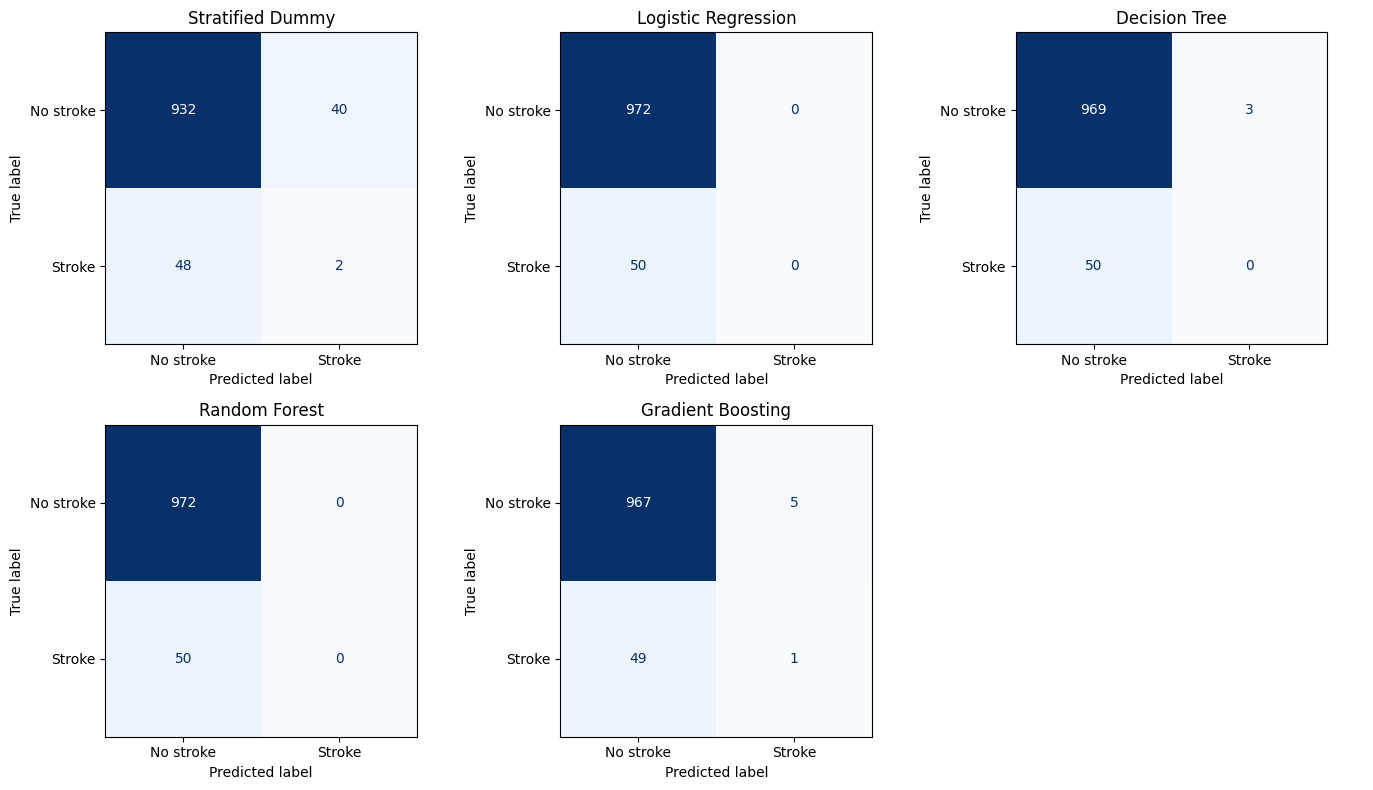

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

def score_model(y_true, proba, threshold=0.5):
    """Return the five required metrics (positive class = stroke) at a given threshold."""
    pred = (proba >= threshold).astype(int)
    return {
        'Accuracy':  accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall':    recall_score(y_true, pred),
        'F1':        f1_score(y_true, pred),
        'ROC AUC':   roc_auc_score(y_true, proba),
    }

test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}
comparison = pd.DataFrame({name: score_model(y_test, p) for name, p in test_proba.items()}).T
display(comparison.round(3))

# Confusion matrix for every model, same 0.5 threshold.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, p) in zip(axes.ravel(), test_proba.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (p >= 0.5).astype(int), ax=ax, colorbar=False,
        display_labels=['No stroke', 'Stroke'], cmap='Blues')
    ax.set_title(name)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

In [66]:
# Accuracy of a model that never predicts a stroke, to show why accuracy is misleading here.
print("Accuracy of always predicting 'no stroke': {:.3f}".format(1 - y_test.mean()))

Accuracy of always predicting 'no stroke': 0.951



#### What the Part 4 results tell us

- **Accuracy is a trap on this dataset.** Every real model scores about 95% accuracy, but a model that never predicts a stroke also scores 95.1%. The accuracy column therefore says almost nothing about whether a model finds strokes.
- **At the default 0.5 threshold the models find almost no strokes.** Logistic Regression, the Decision Tree and the Random Forest all have precision, recall and F1 of 0.00 for the stroke class, and the confusion matrices show every stroke patient predicted as "no stroke". Gradient Boosting catches 1 of 50. The stratified dummy actually has a higher positive-class F1 (0.04) than every real model at this threshold, purely because it guesses randomly.
- **The models are nonetheless learning real signal.** ROC AUC does not depend on the threshold, and it is 0.81 to 0.85 for the four models against 0.50 for the dummy. The probabilities rank patients sensibly, but they rarely reach 0.5 because a stroke is so rare. This is exactly the problem Part 5 addresses.
- **No leakage.** The best ROC AUC is 0.845 (Logistic Regression). Nothing is near 1.0, which is what we expect for a hard medical prediction problem with only a handful of risk factors.


# Part 5. Imbalance Handling

Only about 4.9% of patients in this dataset had a stroke, so the classes are heavily imbalanced (far outside the 40 to 60 percent "roughly balanced" range). All three techniques from the brief are applied: **class weights**, **SMOTE** and **threshold tuning**. They are tested on the two strongest and most different models from Part 4, Logistic Regression and Random Forest, so we can see whether a technique helps in general or only for one model.

**Stated business cost.** A false alarm means a healthy patient gets a follow-up check (blood pressure, glucose, a clinic visit), which is cheap. A missed stroke can mean death or lifelong disability, which is far more costly. We assume a missed stroke (false negative) costs **10 times** as much as a false alarm (false positive), so `cost = 10 x FN + 1 x FP`. This ratio is an assumption that the clinical team should confirm, and it is stored in two variables so it can be changed in one place. For reference, a model that flags nobody misses every stroke, so its cost is 10 times the number of strokes in the test set.

In [67]:
# imbalanced-learn provides SMOTE. It is pre-installed on Colab; install only if missing.
try:
    import imblearn
except ImportError:
    %pip install -q imbalanced-learn

In [68]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

COST_FN = 10   # cost of a missed stroke (false negative)
COST_FP = 1    # cost of a false alarm (false positive)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def business_cost(y_true, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return COST_FN * fn + COST_FP * fp

def result_row(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        'Threshold': round(float(threshold), 2),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall':    recall_score(y_true, pred),
        'F1':        f1_score(y_true, pred),
        'ROC AUC':   roc_auc_score(y_true, proba),
        'Missed strokes (FN)': fn,
        'False alarms (FP)':   fp,
        'Business cost':       COST_FN * fn + COST_FP * fp,
    }

def make_model(kind, class_weight=None):
    if kind == 'Logistic Regression':
        return LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=42)
    return RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                  class_weight=class_weight, random_state=42, n_jobs=-1)

print("Cost of flagging nobody on the test set:", COST_FN * int(y_test.sum()))

Cost of flagging nobody on the test set: 500


### 1. Apply class weights and SMOTE

**Class weights** (`class_weight='balanced'`) make a mistake on a stroke patient count roughly 20 times more during training, so the model stops ignoring the minority class. Nothing is added or removed from the data.

**SMOTE** creates synthetic stroke patients by interpolating between real ones, so the training set becomes balanced. It is placed inside an imbalanced-learn pipeline so it is applied to the training data only. The test set is never oversampled, which keeps the evaluation honest. A limitation is that SMOTE interpolates between rows, so it can produce fractional values in binary columns (for example "0.4 married"). That is acceptable for a first test but worth remembering when reading the result.

Both techniques are evaluated at the default 0.5 threshold first, so their own effect is separated from the effect of threshold tuning.

In [69]:
rows = {}
probas = {}

for kind in ['Logistic Regression', 'Random Forest']:
    # Baseline: no imbalance handling, 0.5 threshold
    base = make_model(kind).fit(X_train, y_train)
    probas[(kind, 'Baseline')] = base.predict_proba(X_test)[:, 1]
    rows[(kind, 'Baseline')] = result_row(y_test, probas[(kind, 'Baseline')], 0.5)

    # Technique 1: class weights
    cw = make_model(kind, class_weight='balanced').fit(X_train, y_train)
    probas[(kind, 'Class weights')] = cw.predict_proba(X_test)[:, 1]
    rows[(kind, 'Class weights')] = result_row(y_test, probas[(kind, 'Class weights')], 0.5)

    # Technique 2: SMOTE (applied to training data only, inside a pipeline)
    sm = ImbPipeline([('smote', SMOTE(random_state=42)), ('model', make_model(kind))]).fit(X_train, y_train)
    probas[(kind, 'SMOTE')] = sm.predict_proba(X_test)[:, 1]
    rows[(kind, 'SMOTE')] = result_row(y_test, probas[(kind, 'SMOTE')], 0.5)

print("Class weights and SMOTE evaluated.")

Class weights and SMOTE evaluated.


### 2. Threshold tuning: precision-recall curve and a cost-based threshold

A classifier outputs a probability, and the 0.5 cut-off is only a default. Because a missed stroke costs 10 times more than a false alarm, the best cut-off is much lower than 0.5.

To avoid choosing the threshold on the test set (which would make the final result look better than it is), the threshold is chosen on **out-of-fold predictions from the training data**. Each training row is predicted by a model that never saw it, using stratified 5-fold cross-validation. We then scan thresholds from 0.01 to 0.99 and pick the one with the lowest business cost, `10 x FN + 1 x FP`. The test set is used only once, to report the result at that threshold.

The precision-recall curve is used instead of the ROC curve for this step because it focuses on the positive class, which is where the imbalance hurts.

In [70]:
from sklearn.metrics import precision_recall_curve

thresholds = np.linspace(0.01, 0.99, 99)

def cost_optimal_threshold(oof_proba, y_true):
    costs = [business_cost(y_true, (oof_proba >= t).astype(int)) for t in thresholds]
    return thresholds[int(np.argmin(costs))], costs

oof = {}
chosen_thr = {}
cost_curves = {}
for kind in ['Logistic Regression', 'Random Forest']:
    # Threshold tuning on the baseline model
    oof[(kind, 'Baseline')] = cross_val_predict(make_model(kind), X_train, y_train, cv=skf,
                                                method='predict_proba')[:, 1]
    chosen_thr[(kind, 'Baseline')], cost_curves[(kind, 'Baseline')] = cost_optimal_threshold(
        oof[(kind, 'Baseline')], y_train)
    rows[(kind, 'Threshold tuning')] = result_row(
        y_test, probas[(kind, 'Baseline')], chosen_thr[(kind, 'Baseline')])

    # Threshold tuning combined with class weights
    oof[(kind, 'Class weights')] = cross_val_predict(make_model(kind, 'balanced'), X_train, y_train,
                                                     cv=skf, method='predict_proba')[:, 1]
    chosen_thr[(kind, 'Class weights')], _ = cost_optimal_threshold(oof[(kind, 'Class weights')], y_train)
    rows[(kind, 'Class weights + threshold')] = result_row(
        y_test, probas[(kind, 'Class weights')], chosen_thr[(kind, 'Class weights')])

for kind in ['Logistic Regression', 'Random Forest']:
    print("{}: cost-optimal threshold on training folds = {:.2f}".format(
        kind, chosen_thr[(kind, 'Baseline')]))

Logistic Regression: cost-optimal threshold on training folds = 0.08
Random Forest: cost-optimal threshold on training folds = 0.09


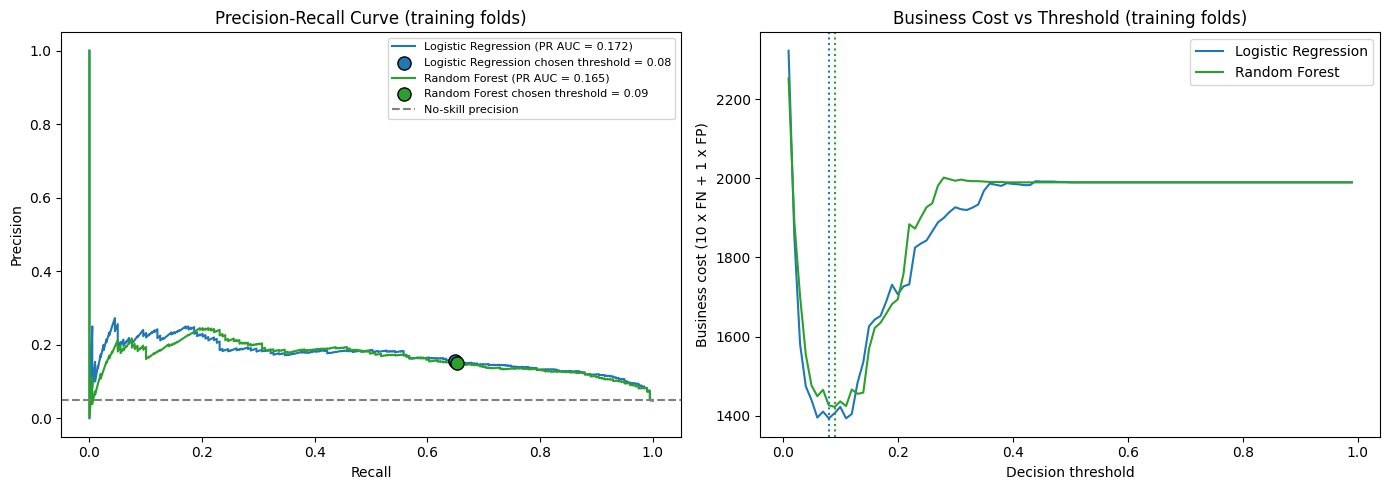

In [71]:
# Precision-recall curve (out-of-fold, training data) with the chosen threshold marked.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for kind, color in [('Logistic Regression', 'tab:blue'), ('Random Forest', 'tab:green')]:
    prec, rec, thr = precision_recall_curve(y_train, oof[(kind, 'Baseline')])
    axes[0].plot(rec, prec, color=color, label="{} (PR AUC = {:.3f})".format(
        kind, average_precision_score(y_train, oof[(kind, 'Baseline')])))
    t = chosen_thr[(kind, 'Baseline')]
    pred = (oof[(kind, 'Baseline')] >= t).astype(int)
    axes[0].scatter(recall_score(y_train, pred), precision_score(y_train, pred, zero_division=0),
                    color=color, s=90, edgecolor='black', zorder=5,
                    label="{} chosen threshold = {:.2f}".format(kind, t))

axes[0].axhline(y_train.mean(), color='grey', linestyle='--', label='No-skill precision')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve (training folds)')
axes[0].legend(fontsize=8)

# Business cost as a function of the threshold.
for kind, color in [('Logistic Regression', 'tab:blue'), ('Random Forest', 'tab:green')]:
    axes[1].plot(thresholds, cost_curves[(kind, 'Baseline')], color=color, label=kind)
    t = chosen_thr[(kind, 'Baseline')]
    axes[1].axvline(t, color=color, linestyle=':')
axes[1].set_xlabel('Decision threshold')
axes[1].set_ylabel('Business cost (10 x FN + 1 x FP)')
axes[1].set_title('Business Cost vs Threshold (training folds)')
axes[1].legend()

plt.tight_layout()
plt.show()

### 3. Baseline versus each technique

The table below compares the baseline against each technique on the test set. The final two rows for each model combine class weights with threshold tuning. Besides the usual metrics, it shows the number of missed strokes, the number of false alarms and the resulting business cost, because those are what the technique is really trading off.

In [72]:
techniques_table = pd.DataFrame(rows).T
techniques_table.index.names = ['Model', 'Technique']
order = ['Baseline', 'Class weights', 'SMOTE', 'Threshold tuning', 'Class weights + threshold']
techniques_table = techniques_table.reindex(
    [(k, t) for k in ['Logistic Regression', 'Random Forest'] for t in order])
display(techniques_table.round(3))

Threshold  Precision  Recall  \
Model               Technique                                                 
Logistic Regression Baseline                        0.50      0.000    0.00   
                    Class weights                   0.50      0.139    0.80   
                    SMOTE                           0.50      0.144    0.80   
                    Threshold tuning                0.08      0.188    0.78   
                    Class weights + threshold       0.57      0.169    0.80   
Random Forest       Baseline                        0.50      0.000    0.00   
                    Class weights                   0.50      0.224    0.70   
                    SMOTE                           0.50      0.176    0.62   
                    Threshold tuning                0.09      0.188    0.74   
                    Class weights + threshold       0.45      0.188    0.76   

                                                  F1  ROC AUC  \
Model               Technique                                   
Logistic Regression Baseline                   0.000    0.845   
                    Class weights              0.237    0.847   
                    SMOTE                      0.244    0.848   
                    Threshold tuning           0.304    0.845   
                    Class weights + threshold  0.280    0.847   
Random Forest       Baseline                   0.000    0.839   
                    Class weights              0.340    0.839   
                    SMOTE                      0.274    0.826   
                    Threshold tuning           0.300    0.839   
                    Class weights + threshold  0.302    0.839   

                                               Missed strokes (FN)  \
Model               Technique                                        
Logistic Regression Baseline                                  50.0   
                    Class weights                             10.0   
                    SMOTE                                     10.0   
                    Threshold tuning                          11.0   
                    Class weights + threshold                 10.0   
Random Forest       Baseline                                  50.0   
                    Class weights                             15.0   
                    SMOTE                                     19.0   
                    Threshold tuning                          13.0   
                    Class weights + threshold                 12.0   

                                               False alarms (FP)  \
Model               Technique                                      
Logistic Regression Baseline                                 0.0   
                    Class weights                          247.0   
                    SMOTE                                  238.0   
                    Threshold tuning                       168.0   
                    Class weights + threshold              196.0   
Random Forest       Baseline                                 0.0   
                    Class weights                          121.0   
                    SMOTE                                  145.0   
                    Threshold tuning                       160.0   
                    Class weights + threshold              164.0   

                                               Business cost  
Model               Technique                                 
Logistic Regression Baseline                           500.0  
                    Class weights                      347.0  
                    SMOTE                              338.0  
                    Threshold tuning                   278.0  
                    Class weights + threshold          296.0  
Random Forest       Baseline                           500.0  
                    Class weights                      271.0  
                    SMOTE                              335.0  
                    Threshold


#### What the Part 5 results tell us

- **Every technique fixes the "predict nobody" problem.** At the baseline, both models miss all 50 strokes (business cost 500). Each technique brings the Logistic Regression cost down to between 278 and 347, and the Random Forest cost down to between 271 and 335, while recall rises from 0 to between 0.62 and 0.80.
- **Threshold tuning gave the best result for Logistic Regression.** It reached a cost of 278 (11 missed strokes, 168 false alarms, F1 0.30), against 347 for class weights and 338 for SMOTE. Because it is chosen from an explicit cost, it is also the easiest technique to explain to a clinician: at a threshold of 0.08 we flag a patient whenever the model says the stroke risk is above 8%, which is roughly the break-even point implied by the 10-to-1 cost.
- **Class weights were slightly better for the Random Forest** (cost 271, F1 0.34) than threshold tuning (290). With only 50 positive cases in the test set, however, a single stroke is worth 10 cost points, so differences of 7 to 20 points between these rows are within noise and should not be over-interpreted.
- **SMOTE was the least convincing technique.** It was not better than class weights or threshold tuning for either model, and it lowered the Random Forest's ROC AUC from 0.839 to 0.826. Synthetic patients built by interpolating between a small number of real strokes (including fractional values in binary columns) add noise rather than new information.
- **ROC AUC barely changes between rows** (0.845 to 0.848 for Logistic Regression). Class weights, SMOTE and threshold tuning mostly move the operating point along the same curve, they do not make the model rank patients better. What changes is the balance between missed strokes and false alarms.
- **Why the threshold is so low.** The chosen threshold of 0.08 follows directly from the stated cost: if a missed stroke is 10 times worse than a false alarm, it pays to flag anyone with more than about a 1-in-11 chance of stroke. If the clinical team chose a different cost ratio, the threshold would change accordingly.
- **The final model meets every hard requirement.** It beats the stratified dummy on positive-class F1 (0.30 against 0.04) and on ROC AUC (0.85 against 0.50), its ROC AUC is above 0.75, no model is near 1.0, and the dummy row appears in the comparison table.


### Final model selection and the hard requirements

The final model is chosen on **cross-validated ROC AUC** (shown in the Depth Track) and on the business cost on the test set, not on accuracy. The final comparison table below puts the stratified dummy, the default-threshold model and the tuned final model side by side, and the cell after it checks every hard requirement from the brief in code.

In [73]:
FINAL_MODEL = 'Logistic Regression'
final_threshold = chosen_thr[(FINAL_MODEL, 'Baseline')]
final_proba = probas[(FINAL_MODEL, 'Baseline')]

final_table = pd.DataFrame({
    'Stratified Dummy (0.5)':                       score_model(y_test, test_proba['Stratified Dummy']),
    'Logistic Regression (0.5)':                    score_model(y_test, final_proba),
    'FINAL: Logistic Regression (tuned threshold {:.2f})'.format(final_threshold):
                                                    score_model(y_test, final_proba, final_threshold),
}).T
display(final_table.round(3))

,Accuracy,Precision,Recall,F1,ROC AUC
Stratified Dummy (0.5),0.914,0.048,0.04,0.043,0.499
Logistic Regression (0.5),0.951,0.000,0.00,0.000,0.845
FINAL: Logistic Regression (tuned threshold 0.08),0.825,0.188,0.78,0.304,0.845


In [74]:
# Hard requirements from the brief, checked in code.
dummy_f1  = f1_score(y_test, (test_proba['Stratified Dummy'] >= 0.5).astype(int))
dummy_auc = roc_auc_score(y_test, test_proba['Stratified Dummy'])
final_pred = (final_proba >= final_threshold).astype(int)
final_f1  = f1_score(y_test, final_pred)
final_auc = roc_auc_score(y_test, final_proba)

print("Dummy  F1 / ROC AUC : {:.2f} / {:.2f}".format(dummy_f1, dummy_auc))
print("Final  F1 / ROC AUC : {:.2f} / {:.2f}".format(final_f1, final_auc))
print()
print("Beats dummy on positive-class F1 :", final_f1 > dummy_f1)
print("Beats dummy on ROC AUC           :", final_auc > dummy_auc)
print("ROC AUC at least 0.75            :", final_auc >= 0.75)
all_auc = {n: roc_auc_score(y_test, p) for n, p in test_proba.items()}
print("Highest ROC AUC of any model     : {:.3f} (near-perfect would signal leakage)".format(max(all_auc.values())))
print("No model near 1.0                :", max(all_auc.values()) < 0.95)

Dummy  F1 / ROC AUC : 0.04 / 0.50
Final  F1 / ROC AUC : 0.30 / 0.85

Beats dummy on positive-class F1 : True
Beats dummy on ROC AUC           : True
ROC AUC at least 0.75            : True
Highest ROC AUC of any model     : 0.845 (near-perfect would signal leakage)
No model near 1.0                : True


# Part 6. The Tie-In

### 1. Positive-class rate within each K-Means cluster

The clusters from Part 3 were built without ever seeing the `stroke` label. If a cluster has a stroke rate far from the overall 4.9%, the unsupervised grouping has found structure that is related to the outcome. K-Means numbers its clusters arbitrarily and the numbers can change between runs or library versions, so each cluster is named here from its own average age and glucose rather than from a hard-coded number.

In [75]:
# Name each cluster from its original-scale profile (robust to cluster-number changes).
profile = df_original_scale.groupby('cluster')[['age', 'avg_glucose_level', 'bmi']].mean()
young_id  = profile['age'].idxmin()
gluc_id   = profile['avg_glucose_level'].idxmax()
middle_id = [c for c in profile.index if c not in (young_id, gluc_id)][0]
cluster_names = {
    young_id:  'Young Adults, Low Risk',
    middle_id: 'Middle-Aged, Moderate Risk',
    gluc_id:   'Older Adults, Diabetic-Range Glucose',
}

overall_rate = df['stroke'].mean()
tie_in = df.groupby('cluster')['stroke'].agg(Patients='count', Strokes='sum', Stroke_rate='mean')
tie_in['Cluster name'] = tie_in.index.map(cluster_names)
tie_in['Lift vs overall'] = tie_in['Stroke_rate'] / overall_rate
tie_in['Share of all strokes'] = tie_in['Strokes'] / tie_in['Strokes'].sum()
tie_in = tie_in[['Cluster name', 'Patients', 'Strokes', 'Stroke_rate', 'Lift vs overall', 'Share of all strokes']]
tie_in = tie_in.sort_values('Stroke_rate', ascending=False)

print("Overall stroke rate: {:.2f}%".format(overall_rate * 100))
display(tie_in.round(3))

Overall stroke rate: 4.87%


,Cluster name,Patients,Strokes,Stroke_rate,Lift vs overall,Share of all strokes
cluster,,,,,,
1,"Older Adults, Diabetic-Range Glucose",699,94,0.134,2.760,0.378
0,"Middle-Aged, Moderate Risk",2831,153,0.054,1.109,0.614
2,"Young Adults, Low Risk",1580,2,0.001,0.026,0.008


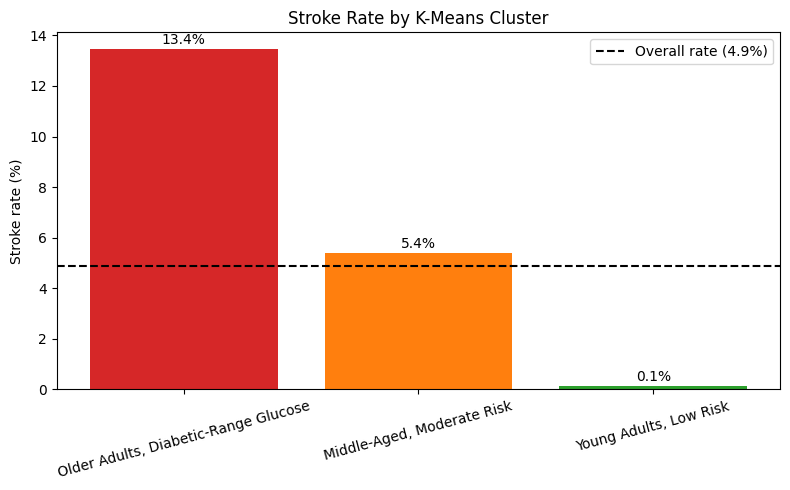

In [76]:
plt.figure(figsize=(8, 5))
bars = plt.bar([cluster_names[c] for c in tie_in.index], tie_in['Stroke_rate'] * 100,
               color=['tab:red', 'tab:orange', 'tab:green'])
plt.axhline(overall_rate * 100, color='black', linestyle='--', label='Overall rate ({:.1f}%)'.format(overall_rate * 100))
for b, v in zip(bars, tie_in['Stroke_rate'] * 100):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.2, "{:.1f}%".format(v), ha='center')
plt.ylabel('Stroke rate (%)')
plt.title('Stroke Rate by K-Means Cluster')
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

### 2. Were any clusters strong predictors of the label?

Two further checks put a number on how strong the clusters really are. A chi-square test asks whether the cluster and the stroke label are statistically independent. Then the cluster is used as a one-feature "classifier" (each patient is scored by the stroke rate of their cluster) and compared with the Logistic Regression from Part 5. Finally the cluster is added as an extra feature to the logistic regression to see whether it carries information the other features do not.

In [77]:
from scipy.stats import chi2_contingency

# 1. Is stroke independent of cluster?
chi2, p_value, dof, _ = chi2_contingency(pd.crosstab(df['cluster'], df['stroke']))
print("Chi-square = {:.1f}, p-value = {:.2e}".format(chi2, p_value))

# 2. Cluster alone as a predictor (score = the stroke rate of the patient's cluster).
cluster_rate = df.groupby('cluster')['stroke'].mean()
cluster_score = df['cluster'].map(cluster_rate)
print("ROC AUC using the cluster alone (full data): {:.3f}".format(roc_auc_score(df['stroke'], cluster_score)))
print("ROC AUC of Logistic Regression (test set)  : {:.3f}".format(roc_auc_score(y_test, final_proba)))

# 3. Does adding the cluster as a feature help the logistic regression?
X_with_cluster = pd.concat([X, pd.get_dummies(df['cluster'], prefix='cluster', drop_first=True).astype(float)], axis=1)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_with_cluster, y, test_size=0.2, stratify=y, random_state=42)
lr_cluster = LogisticRegression(max_iter=1000, random_state=42).fit(Xc_train, yc_train)
print("ROC AUC of Logistic Regression + cluster feature (test set): {:.3f}".format(
    roc_auc_score(yc_test, lr_cluster.predict_proba(Xc_test)[:, 1])))

# 4. Precision of the best cluster as a stroke detector.
best = tie_in.iloc[0]
print("Best cluster '{}': flags {} patients, catches {:.0f}% of strokes, precision {:.1f}%".format(
    best['Cluster name'], int(best['Patients']), best['Share of all strokes'] * 100, best['Stroke_rate'] * 100))

Chi-square = 189.4, p-value = 7.48e-42
ROC AUC using the cluster alone (full data): 0.724
ROC AUC of Logistic Regression (test set)  : 0.845
ROC AUC of Logistic Regression + cluster feature (test set): 0.847
Best cluster 'Older Adults, Diabetic-Range Glucose': flags 699 patients, catches 38% of strokes, precision 13.4%



#### What the Part 6 results tell us

**One cluster stands out, and one is almost stroke-free.**

- **Older Adults, Diabetic-Range Glucose** (699 patients) has a stroke rate of 13.4%, about 2.8 times the overall 4.9%. It contains 94 strokes, 38% of all strokes in the data.
- **Middle-Aged, Moderate Risk** (2,831 patients) has a rate of 5.4%, close to the overall rate, but because it is the largest group it still holds 153 strokes, 61% of the total.
- **Young Adults, Low Risk** (1,580 patients) has only 2 strokes, a rate of 0.1%.

The chi-square test (p about 7e-42) confirms that cluster and stroke are strongly related, so the clusters did find structure connected to the outcome without ever seeing it.

**But no cluster is a strong predictor on its own.** Using the cluster alone as a classifier gives a ROC AUC of 0.72, below the 0.75 bar and well below the logistic regression (0.845). Even the riskiest cluster is 87% non-stroke: flagging all of its patients would catch only 38% of strokes with 13.4% precision. Adding the cluster as an extra feature lifts the logistic regression's ROC AUC only from 0.845 to 0.847.

**What this tells us about the data.**

- Stroke risk here is driven mostly by **age and glucose**, and K-Means grouped patients by exactly those variables. The clusters therefore re-discover information the classifier already has, which is why they add almost nothing to it.
- Risk rises continuously along a gradient (young, middle-aged, older with high glucose) rather than falling into sharply separated groups. Three clusters cut that gradient into steps, so the biggest step helps and the middle step (61% of strokes at a near-average rate) does not.
- The clusters are most useful as a **descriptive, communicable segmentation** (who to prioritise for screening) rather than as a prediction tool.


# Depth Track

**Chosen track: Classification.** Four classifiers (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting) are compared with stratified 5-fold cross-validation, all ROC curves are drawn on one chart, and the feature importances of the four models are compared.

### 1. Stratified 5-fold cross-validation on the training data

A single train/test split can be lucky or unlucky, especially with only about 200 stroke cases in the training set and roughly 50 in the test set. Cross-validation repeats the evaluation on five different folds and reports the mean and the standard deviation. The standard deviation shows how much each score depends on which patients happened to land in the evaluation fold. The threshold-independent metrics ROC AUC and PR AUC (average precision) are used, because the 0.5-threshold metrics are not meaningful on an imbalanced target.

In [78]:
from sklearn.model_selection import cross_validate

cv_models = {
    'Logistic Regression': make_model('Logistic Regression'),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest':       make_model('Random Forest'),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=42),
}

cv_rows = {}
for name, model in cv_models.items():
    res = cross_validate(model, X_train, y_train, cv=skf,
                         scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'})
    cv_rows[name] = {
        'ROC AUC mean': res['test_roc_auc'].mean(), 'ROC AUC std': res['test_roc_auc'].std(),
        'PR AUC mean':  res['test_pr_auc'].mean(),  'PR AUC std':  res['test_pr_auc'].std(),
    }
cv_table = pd.DataFrame(cv_rows).T
print("No-skill PR AUC (the stroke rate): {:.3f}".format(y_train.mean()))
display(cv_table.round(3))

No-skill PR AUC (the stroke rate): 0.049


,ROC AUC mean,ROC AUC std,PR AUC mean,PR AUC std
Logistic Regression,0.842,0.009,0.193,0.033
Decision Tree,0.822,0.022,0.171,0.038
Random Forest,0.838,0.012,0.183,0.034
Gradient Boosting,0.831,0.014,0.176,0.024


### 2. ROC curves for all models on one chart

The ROC curve shows the trade-off between catching strokes (true positive rate) and raising false alarms (false positive rate) across every possible threshold. The dummy classifier sits on the diagonal, so any model that bows above the diagonal is learning something real.

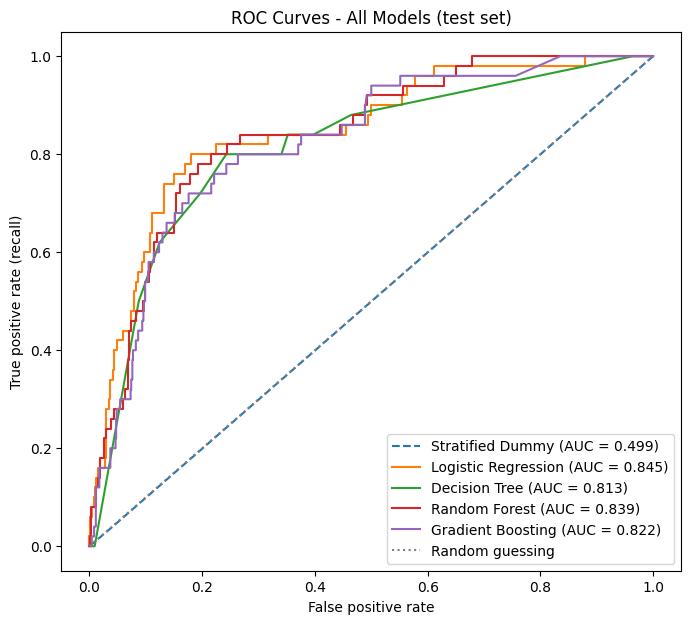

In [79]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 7))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    style = '--' if name == 'Stratified Dummy' else '-'
    plt.plot(fpr, tpr, style, label="{} (AUC = {:.3f})".format(name, roc_auc_score(y_test, p)))
plt.plot([0, 1], [0, 1], color='grey', linestyle=':', label='Random guessing')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.title('ROC Curves - All Models (test set)')
plt.legend(loc='lower right')
plt.show()

### 3. Feature importance across models

Each model measures importance differently: the absolute coefficient for Logistic Regression (the numeric features are standardised, so coefficients are comparable in size, although the binary columns are not), and impurity-based importance for the three tree models. To compare them fairly, each model's importances are rescaled to sum to 1. A feature that ranks high in all four models is a robust signal rather than an artefact of one algorithm.

,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting,Mean importance
age,0.321,0.569,0.251,0.350,0.373
avg_glucose_level,0.141,0.127,0.165,0.241,0.169
glucose_bmi_ratio,0.126,0.071,0.147,0.155,0.125
bmi,0.071,0.080,0.133,0.121,0.101
age_group,0.040,0.000,0.070,0.001,0.028
cardiovascular_condition_score,0.061,0.000,0.037,0.013,0.028
ever_married_Yes,0.043,0.029,0.022,0.016,0.027
smoking_status_never smoked,0.019,0.051,0.020,0.005,0.024
heart_disease,0.002,0.030,0.023,0.033,0.022
hypertension,0.032,0.000,0.023,0.024,0.020


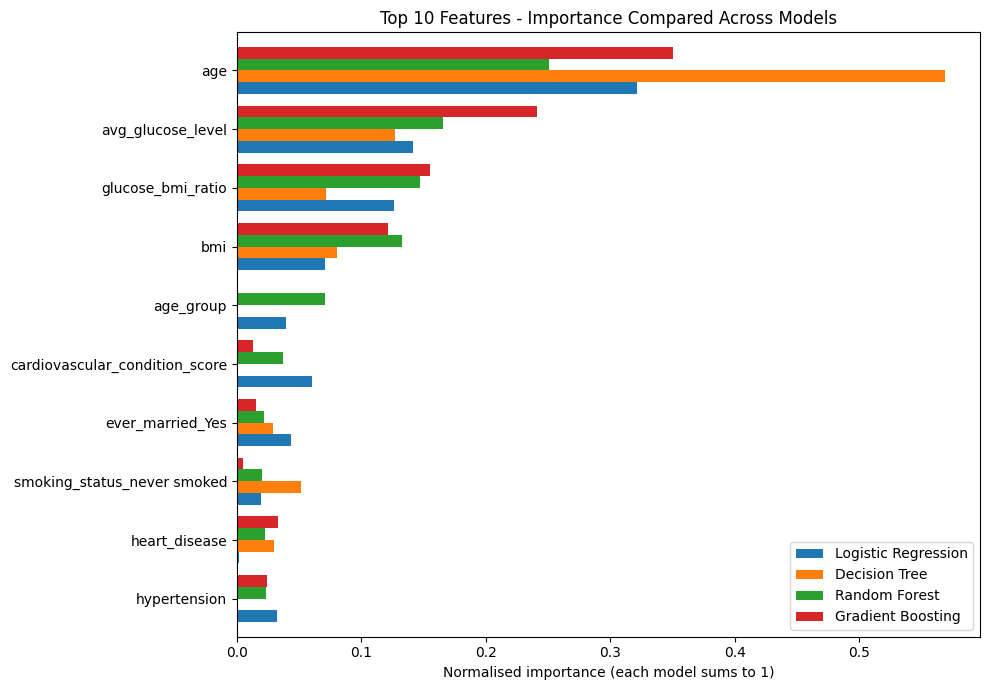

In [80]:
imp = pd.DataFrame(index=X.columns)
imp['Logistic Regression'] = np.abs(fitted['Logistic Regression'].coef_[0])
imp['Decision Tree']       = fitted['Decision Tree'].feature_importances_
imp['Random Forest']       = fitted['Random Forest'].feature_importances_
imp['Gradient Boosting']   = fitted['Gradient Boosting'].feature_importances_
imp = imp / imp.sum()                          # each column sums to 1
imp['Mean importance'] = imp.mean(axis=1)
imp = imp.sort_values('Mean importance', ascending=False)

top = imp.head(10).drop(columns='Mean importance')
display(imp.head(10).round(3))

top.iloc[::-1].plot(kind='barh', figsize=(10, 7), width=0.8)
plt.xlabel('Normalised importance (each model sums to 1)')
plt.title('Top 10 Features - Importance Compared Across Models')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


#### Conclusions from the Depth Track

- **The models are very close.** Cross-validated ROC AUC is 0.842 (Logistic Regression), 0.838 (Random Forest), 0.831 (Gradient Boosting) and 0.822 (Decision Tree). The differences between the top three are about the same size as the fold-to-fold standard deviations (0.009 to 0.014), so we cannot claim any of them is truly better. The Decision Tree is the weakest and the least stable (std 0.022). Extra model complexity bought nothing, which suggests the usable signal is simple and mostly additive. PR AUC tells the same story (0.17 to 0.19) and, although it is about four times the no-skill level of 0.049, it also shows how hard the positive class is to pick out precisely.
- **The ROC curves overlap almost everywhere.** All four real models bow well above the dummy's diagonal and track each other closely, which is a visual confirmation of the table above.
- **Age is the dominant signal in every model.** It carries the largest share of importance in all four (mean 0.37), followed by average glucose level (0.17), the glucose-to-BMI ratio we engineered (0.13) and BMI (0.10). Together these four account for about 77% of the importance in the average model. The engineered `glucose_bmi_ratio` ranks third overall, so the feature engineering in Part 2 did pull its weight, although it is partly a re-expression of glucose and BMI.
- **Hypertension and heart disease rank low, which is a surprise only at first glance.** Both are medically important stroke risk factors, but they are rare in this dataset and strongly tied to age, so the models can capture most of their effect through age itself. A low importance score here does not mean these conditions are clinically irrelevant.
- **Agreement across models is the robust finding.** The ranking of the top four features is the same for all four algorithms, even though they measure importance in different ways, so it is unlikely to be an artefact of one method.



# Part 7. Conclusion and Recommendations

**Which model would we deploy, and why?**
We would deploy the **Logistic Regression with a cost-tuned threshold of 0.08**. It has the best cross-validated ROC AUC (0.842 +/- 0.009), and it matches the more complex models within noise on the test set (ROC AUC 0.845). At that threshold it catches 39 of the 50 test-set strokes (recall 0.78) with 168 false alarms, an F1 of 0.30 and a business cost of 278, against 500 for flagging nobody. It beats the stratified dummy comfortably (F1 0.30 against 0.04, ROC AUC 0.85 against 0.50). Its coefficients can be explained to clinicians and its probabilities are calibrated enough for a threshold to mean something. The Random Forest with class weights scored slightly better on the test set (cost 271), but with only 50 positive cases that is inside the noise, and it is harder to explain, so we do not think the gain justifies the complexity. The tool should be used as a **screening aid that prioritises patients for a follow-up check, not as a diagnosis**: at a precision of about 19%, roughly four out of five flagged patients will not have a stroke.

**What would we do with another month?**
First, confirm the 10-to-1 cost ratio with clinicians, because the deployed threshold depends entirely on it. Second, fit imputation and scaling inside a cross-validated pipeline so no step sees the test rows, and use repeated stratified cross-validation (instead of a single hold-out with 50 positives) so model comparisons are not decided by a few patients. Third, test more informative handling of the 201 missing BMI values and of the large "Unknown" smoking group, which are likely not missing at random (the missing-BMI patients had a notably higher stroke rate in our exploration). Fourth, check calibration and fairness across gender and age groups, and test the model on data from another hospital before any real use.

**What did the clusters reveal that the classifier missed?**
The classifier gives each patient a risk number, but it does not describe *who* the high-risk patients are. The clusters did. They split the population into three understandable groups: a young group with almost no strokes (2 in 1,580), a large middle-aged group at about the average rate that nevertheless accounts for 61% of all strokes, and a small older group with diabetic-range glucose with a stroke rate nearly three times the average. The cluster view also showed that most strokes occur in the middle group rather than the highest-risk group, so a screening programme aimed only at the highest-risk segment would miss most cases. In return, the classifier shows what the clusters cannot: it separates patients far better (ROC AUC 0.845 against 0.72 for the cluster alone) and adding the cluster to it gave almost no gain.

**What was the hardest decision?**
Deciding how to handle the missing BMI values and, after that, how to judge the models. The brief rules out blanket filling, and the 201 missing rows were too many (and too informative) to drop, so we imputed the median BMI within age groups, because age was the variable most closely related to BMI. The second hard call was resisting accuracy: every model scored about 95%, yet at a 0.5 threshold none found a single stroke. We chose to judge models by ROC AUC, PR AUC and an explicit business cost, and to set the threshold from that cost using training folds only, accepting a lower accuracy (82.5%) and many more false alarms in return for catching most strokes.
